# Fig3 Performance Comparison

**Figure 3** — Comparative model performance (6 panels: RMSE, MAE, R², improvement, recall, bias).

Run this notebook to reproduce Figure 3 for the manuscript (3000×1800 px, 150 DPI).

> **Run cells in order: Cell 1 → Cell 2 → Cell 3**

In [1]:
# Install / upgrade required libraries
!pip install matplotlib numpy pandas scikit-learn -q



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Global constants (real project results) ──
DPI   = 150
W_IN  = 3000 / DPI   # 20 inches
H_IN  = 1800 / DPI   # 12 inches
BG    = '#F7F9FC'

CITIES        = ['Riyadh', 'Jeddah', 'Abha', 'Dammam', 'Qassim']
SEASONS       = ['Spring', 'Summer', 'Autumn', 'Winter']
MONTHS        = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
CITY_COLORS   = ['#1F4E79','#2E75B6','#C00000','#ED7D31','#70AD47']
SEASON_COLORS = {'Spring':'#70AD47','Summer':'#ED7D31','Autumn':'#C00000','Winter':'#1F4E79'}

BASELINE = {
    'Riyadh':  dict(rmse=51.68, mae=25.57, r2=0.9747, bias=-4.04,  paper=100.6),
    'Jeddah':  dict(rmse=49.49, mae=25.93, r2=0.9769, bias=-6.20,  paper=101.0),
    'Abha':    dict(rmse=67.70, mae=39.89, r2=0.9562, bias=-8.83,  paper=107.4),
    'Dammam':  dict(rmse=49.19, mae=25.45, r2=0.9758, bias=-3.50,  paper=92.4),
    'Qassim':  dict(rmse=47.28, mae=24.72, r2=0.9785, bias=-0.30,  paper=97.7),
}
META = {
    'Riyadh':  dict(before=4.8,  after=67.1, failures=289),
    'Jeddah':  dict(before=12.5, after=49.2, failures=313),
    'Abha':    dict(before=2.0,  after=77.8, failures=641),
    'Dammam':  dict(before=7.8,  after=52.6, failures=293),
    'Qassim':  dict(before=2.1,  after=59.7, failures=288),
}
SEASONAL_RECALL = {
    'Riyadh':  dict(Spring=4.8,  Summer=0.7,  Autumn=12.2, Winter=15.3),
    'Jeddah':  dict(Spring=4.9,  Summer=3.6,  Autumn=11.0, Winter=16.8),
    'Abha':    dict(Spring=3.8,  Summer=2.3,  Autumn=12.1, Winter=12.4),
    'Dammam':  dict(Spring=5.7,  Summer=0.7,  Autumn=12.1, Winter=16.9),
    'Qassim':  dict(Spring=3.9,  Summer=0.1,  Autumn=12.0, Winter=16.3),
}
print('✓ Setup complete — ready to run figure cell')


✓ Setup complete — ready to run figure cell


## Figure 3 — Comparative Model Performance (6 panels)
**Purpose:** Main results figure — RMSE, MAE, R², improvement %, recall before/after SMOTE, bias.  
**Section in paper:** Section 4 — Results.  
**Key finding:** 37–52% RMSE reduction vs benchmark; recall improved ×4–×39 after SMOTE.


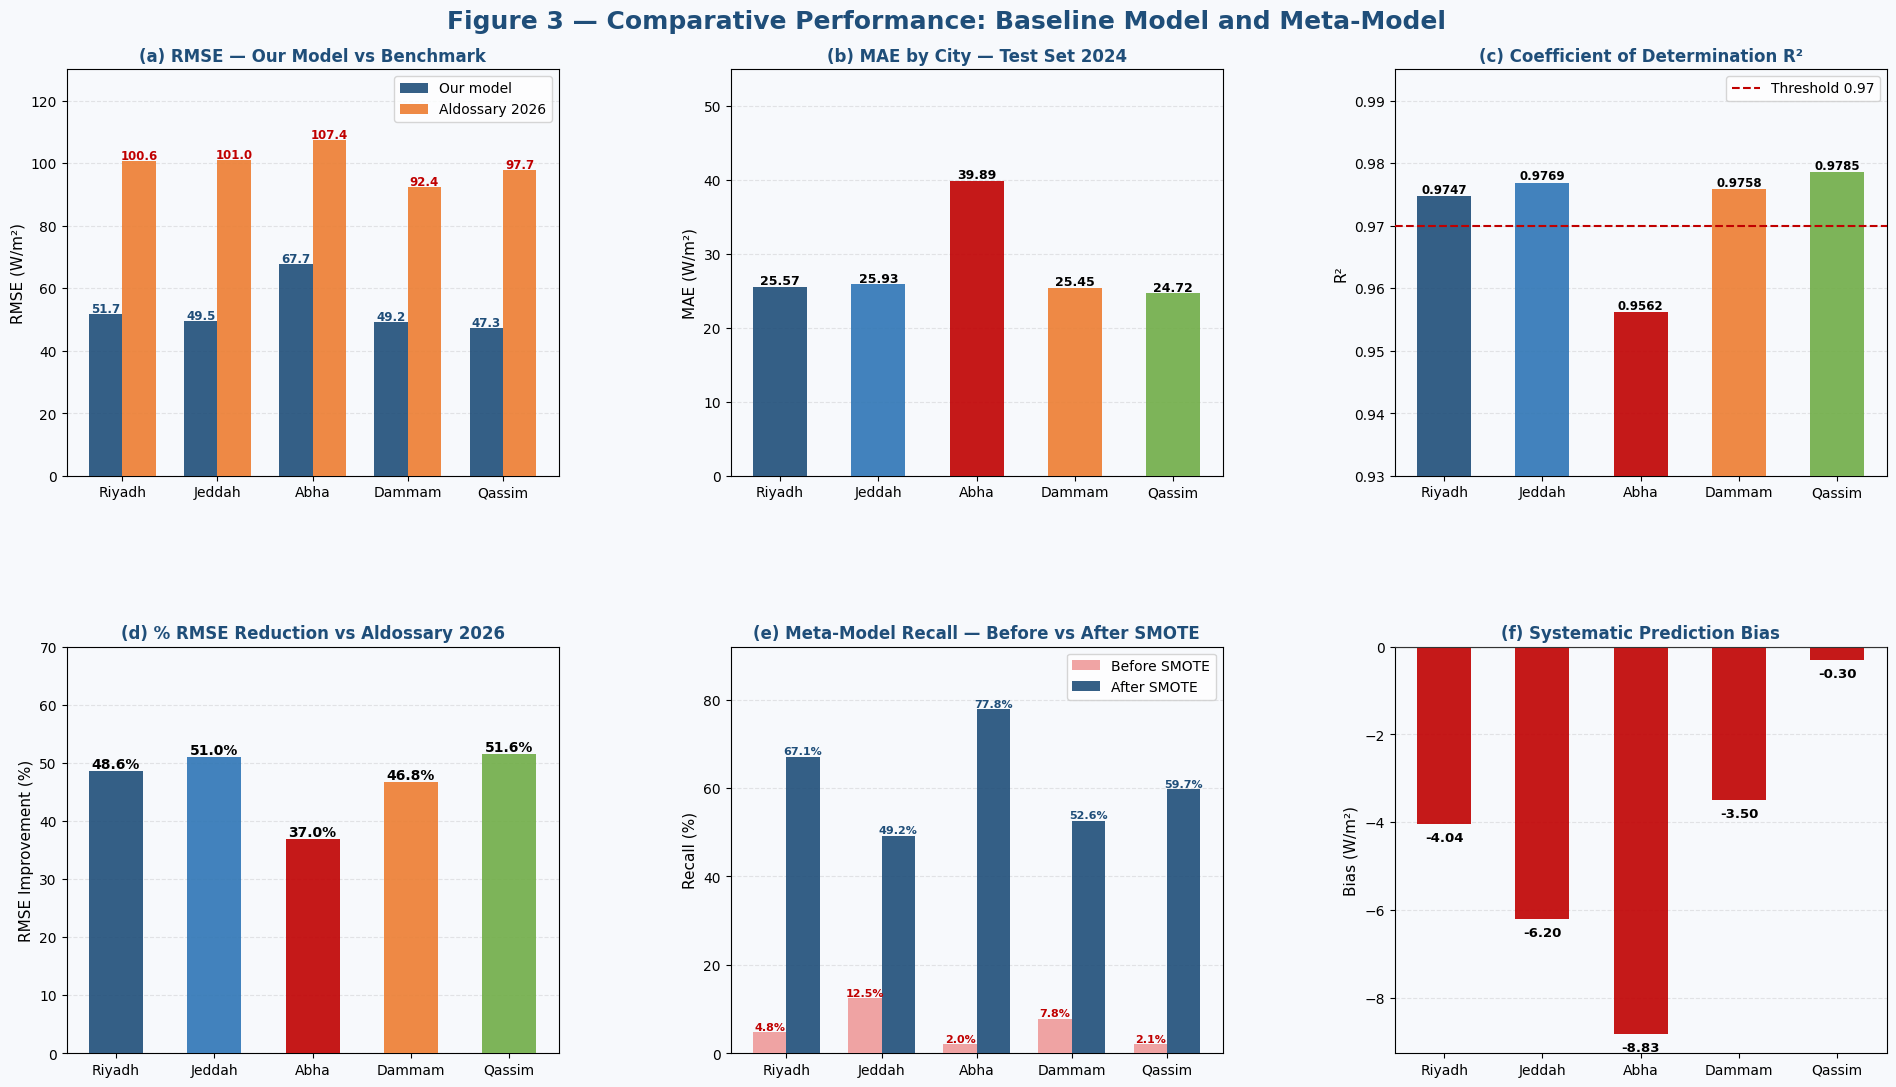

✓ Saved: fig3_performance_comparison.png  (3000×1800 px)


In [3]:
fig = plt.figure(figsize=(W_IN, H_IN))
fig.patch.set_facecolor(BG)
fig.suptitle('Figure 3 — Comparative Performance: Baseline Model and Meta-Model',
             fontsize=18, fontweight='bold', color='#1F4E79', y=0.97)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.35,
                       left=0.06, right=0.97, top=0.92, bottom=0.10)
x = np.arange(len(CITIES)); w = 0.35

# ── Panel (a): RMSE Our vs Paper ──
ax1 = fig.add_subplot(gs[0,0])
ax1.set_facecolor(BG); ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
our   = [BASELINE[c]['rmse']  for c in CITIES]
paper = [BASELINE[c]['paper'] for c in CITIES]
b1 = ax1.bar(x-w/2, our,   w, label='Our model', color='#1F4E79', alpha=0.9, zorder=3)
b2 = ax1.bar(x+w/2, paper, w, label='Aldossary 2026', color='#ED7D31', alpha=0.9, zorder=3)
for bar in b1: ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                         f'{bar.get_height():.1f}', ha='center', fontsize=8.5,
                         fontweight='bold', color='#1F4E79')
for bar in b2: ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                         f'{bar.get_height():.1f}', ha='center', fontsize=8.5,
                         fontweight='bold', color='#C00000')
ax1.set_xticks(x); ax1.set_xticklabels(CITIES, fontsize=10)
ax1.set_ylabel('RMSE (W/m²)', fontsize=11); ax1.set_ylim(0,130)
ax1.set_title('(a) RMSE — Our Model vs Benchmark', fontsize=12, fontweight='bold', color='#1F4E79')
ax1.legend(fontsize=10); ax1.tick_params(labelsize=10)

# ── Panel (b): MAE ──
ax2 = fig.add_subplot(gs[0,1])
ax2.set_facecolor(BG); ax2.grid(True, linestyle='--', alpha=0.3, axis='y')
mae  = [BASELINE[c]['mae'] for c in CITIES]
bars = ax2.bar(x, mae, 0.55, color=CITY_COLORS, alpha=0.9, zorder=3)
for bar, val in zip(bars, mae):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{val:.2f}', ha='center', fontsize=9, fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(CITIES, fontsize=10)
ax2.set_ylabel('MAE (W/m²)', fontsize=11); ax2.set_ylim(0,55)
ax2.set_title('(b) MAE by City — Test Set 2024', fontsize=12, fontweight='bold', color='#1F4E79')
ax2.tick_params(labelsize=10)

# ── Panel (c): R² ──
ax3 = fig.add_subplot(gs[0,2])
ax3.set_facecolor(BG); ax3.grid(True, linestyle='--', alpha=0.3, axis='y')
r2vals = [BASELINE[c]['r2'] for c in CITIES]
bars   = ax3.bar(x, r2vals, 0.55, color=CITY_COLORS, alpha=0.9, zorder=3)
ax3.axhline(0.97, color='#C00000', linestyle='--', lw=1.5, label='Threshold 0.97', zorder=4)
for bar, val in zip(bars, r2vals):
    ax3.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0005,
             f'{val:.4f}', ha='center', fontsize=8.5, fontweight='bold')
ax3.set_xticks(x); ax3.set_xticklabels(CITIES, fontsize=10)
ax3.set_ylabel('R²', fontsize=11); ax3.set_ylim(0.93, 0.995)
ax3.set_title('(c) Coefficient of Determination R²', fontsize=12, fontweight='bold', color='#1F4E79')
ax3.legend(fontsize=10); ax3.tick_params(labelsize=10)

# ── Panel (d): % RMSE improvement ──
ax4 = fig.add_subplot(gs[1,0])
ax4.set_facecolor(BG); ax4.grid(True, linestyle='--', alpha=0.3, axis='y')
improv = [(1-BASELINE[c]['rmse']/BASELINE[c]['paper'])*100 for c in CITIES]
bars   = ax4.bar(x, improv, 0.55, color=CITY_COLORS, alpha=0.9, zorder=3)
for bar, val in zip(bars, improv):
    ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
             f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax4.set_xticks(x); ax4.set_xticklabels(CITIES, fontsize=10)
ax4.set_ylabel('RMSE Improvement (%)', fontsize=11); ax4.set_ylim(0,70)
ax4.set_title('(d) % RMSE Reduction vs Aldossary 2026', fontsize=12, fontweight='bold', color='#1F4E79')
ax4.tick_params(labelsize=10)

# ── Panel (e): Recall before/after SMOTE ──
ax5 = fig.add_subplot(gs[1,1])
ax5.set_facecolor(BG); ax5.grid(True, linestyle='--', alpha=0.3, axis='y')
bef = [META[c]['before'] for c in CITIES]
aft = [META[c]['after']  for c in CITIES]
ax5.bar(x-w/2, bef, w, label='Before SMOTE', color='#ef9a9a', alpha=0.9, zorder=3)
ax5.bar(x+w/2, aft, w, label='After SMOTE',  color='#1F4E79', alpha=0.9, zorder=3)
for xi,(b,a) in enumerate(zip(bef,aft)):
    ax5.text(xi-w/2, b+0.5, f'{b:.1f}%', ha='center', fontsize=8, color='#C00000', fontweight='bold')
    ax5.text(xi+w/2, a+0.5, f'{a:.1f}%', ha='center', fontsize=8, color='#1F4E79', fontweight='bold')
ax5.set_xticks(x); ax5.set_xticklabels(CITIES, fontsize=10)
ax5.set_ylabel('Recall (%)', fontsize=11); ax5.set_ylim(0,92)
ax5.set_title('(e) Meta-Model Recall — Before vs After SMOTE', fontsize=12, fontweight='bold', color='#1F4E79')
ax5.legend(fontsize=10); ax5.tick_params(labelsize=10)

# ── Panel (f): Bias ──
ax6 = fig.add_subplot(gs[1,2])
ax6.set_facecolor(BG); ax6.grid(True, linestyle='--', alpha=0.3, axis='y')
bias        = [BASELINE[c]['bias'] for c in CITIES]
colors_bias = ['#C00000' if b<0 else '#70AD47' for b in bias]
bars = ax6.bar(x, bias, 0.55, color=colors_bias, alpha=0.9, zorder=3)
ax6.axhline(0, color='#333', lw=1.5, zorder=4)
for bar, val in zip(bars, bias):
    ypos = val-0.4 if val<0 else val+0.1
    ax6.text(bar.get_x()+bar.get_width()/2, ypos, f'{val:.2f}',
             ha='center', fontsize=9.5, fontweight='bold')
ax6.set_xticks(x); ax6.set_xticklabels(CITIES, fontsize=10)
ax6.set_ylabel('Bias (W/m²)', fontsize=11)
ax6.set_title('(f) Systematic Prediction Bias', fontsize=12, fontweight='bold', color='#1F4E79')
ax6.tick_params(labelsize=10)

plt.savefig('fig3_performance_comparison.png', dpi=DPI, bbox_inches='tight', facecolor=BG)
plt.show()
print('✓ Saved: fig3_performance_comparison.png  (3000×1800 px)')
